In [17]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import time
from matplotlib.patches import Patch

In [26]:
BASE_URL = "https://api.openf1.org/v1"
ANIOS = [2023, 2025]

# Grupos de edad
GRUPOS_EDAD = [
    "43+",
    "38-42",
    "33-37",
    "28-32",
    "23-27",
    "18-22"
]


In [27]:
def consultar(endpoint, params=None, intentos=5):

    for intento in range(intentos):

        respuesta = requests.get(
            f"{BASE_URL}/{endpoint}",
            params=params,
            timeout=30
        )

        if respuesta.status_code == 429:

            espera = int(
                respuesta.headers.get("Retry-After", 15)
            )

            espera = max(espera, 5)

            print(
                f"Demasiadas peticiones. "
                f"Esperando {espera} segundos..."
            )

            time.sleep(espera)
            continue

        respuesta.raise_for_status()
        return respuesta.json()

    raise RuntimeError(
        "OpenF1 sigue limitando las peticiones."
    )

def obtener_pilotos_temporada(anio):

    print(f"\nConsultando temporada {anio}...")

    # ----------------------------------------------
    # Obtener las carreras de la temporada
    # ----------------------------------------------

    sesiones = pd.DataFrame(
        consultar(
            "sessions",
            params={
                "year": anio,
                "session_name": "Race"
            }
        )
    )

    if sesiones.empty:
        raise ValueError(
            f"No se encontraron carreras en {anio}."
        )

    sesiones["date_start"] = pd.to_datetime(
        sesiones["date_start"],
        format="mixed",
        utc=True
    )

    # Fecha de la última carrera
    fecha_final = sesiones["date_start"].max()

    print(f"Última carrera: {fecha_final.date()}")

    # ----------------------------------------------
    # Obtener pilotos desde Jolpica
    # ----------------------------------------------

    url = (
        f"https://api.jolpi.ca/ergast/f1/"
        f"{anio}/drivers.json"
    )

    respuesta = requests.get(
        url,
        timeout=30
    )

    if respuesta.status_code == 429:
        espera = int(
            respuesta.headers.get("Retry-After", 15)
        )
        time.sleep(max(espera, 5))
        respuesta = requests.get(url, timeout=30)

    respuesta.raise_for_status()

    contenido = respuesta.json()

    lista_pilotos = (
        contenido["MRData"]
        ["DriverTable"]
        ["Drivers"]
    )

    datos = pd.DataFrame(lista_pilotos)

    if datos.empty:
        raise ValueError(
            f"No se encontraron pilotos en {anio}."
        )

    # ----------------------------------------------
    # Seleccionar columnas necesarias
    # ----------------------------------------------

    datos = datos[
        [
            "driverId",
            "givenName",
            "familyName",
            "dateOfBirth"
        ]
    ].copy()

    datos["nombre"] = (
        datos["givenName"]
        + " "
        + datos["familyName"]
    )

    datos["fecha_nacimiento"] = pd.to_datetime(
        datos["dateOfBirth"],
        errors="coerce"
    )

    datos = datos.dropna(
        subset=["fecha_nacimiento"]
    ).copy()

    # ----------------------------------------------
    # Calcular edad en la última carrera
    # ----------------------------------------------

    fecha_referencia = fecha_final.date()

    datos["edad"] = datos["fecha_nacimiento"].apply(
        lambda nacimiento: (
            fecha_referencia.year
            - nacimiento.year
            - (
                (
                    fecha_referencia.month,
                    fecha_referencia.day
                )
                <
                (
                    nacimiento.month,
                    nacimiento.day
                )
            )
        )
    )

    # Guardar temporada
    datos["temporada"] = anio

    print(
        f"Pilotos encontrados: {len(datos)}"
    )

    print(
        f"Edad media: {datos['edad'].mean():.1f} años"
    )

    return datos


In [ ]:
# ==================================================
# 4. OBTENER LOS DATOS DE 2023 Y 2025
# ==================================================

datos_temporadas = []

for anio in ANIOS:

    datos_anio = obtener_pilotos_temporada(anio)

    datos_temporadas.append(datos_anio)

    time.sleep(1)


# Unir las dos temporadas
datos = pd.concat(
    datos_temporadas,
    ignore_index=True
)


Consultando temporada 2023...
Última carrera: 2023-11-26
Pilotos encontrados: 22
Edad media: 28.4 años

Consultando temporada 2025...
Última carrera: 2025-12-07
Pilotos encontrados: 18
Edad media: 26.7 años


In [29]:
# ==================================================
# 5. CREAR LOS GRUPOS DE EDAD
# ==================================================

def asignar_grupo(edad):

    if edad >= 43:
        return "43+"

    elif edad >= 38:
        return "38-42"

    elif edad >= 33:
        return "33-37"

    elif edad >= 28:
        return "28-32"

    elif edad >= 23:
        return "23-27"

    else:
        return "18-22"


datos["grupo_edad"] = datos["edad"].apply(
    asignar_grupo
)

# Eliminar posibles edades inferiores a 18
datos = datos[
    datos["edad"] >= 18
].copy()


In [30]:
# ==================================================
# 6. CALCULAR EL NÚMERO DE PILOTOS POR EDAD
# ==================================================

resumen = datos.pivot_table(
    index="grupo_edad",
    columns="temporada",
    values="driverId",
    aggfunc="count",
    fill_value=0
)

# Asegurar que aparecen todos los grupos
resumen = resumen.reindex(
    GRUPOS_EDAD,
    fill_value=0
)

# Asegurar que aparecen ambas temporadas
resumen = resumen.reindex(
    columns=ANIOS,
    fill_value=0
)


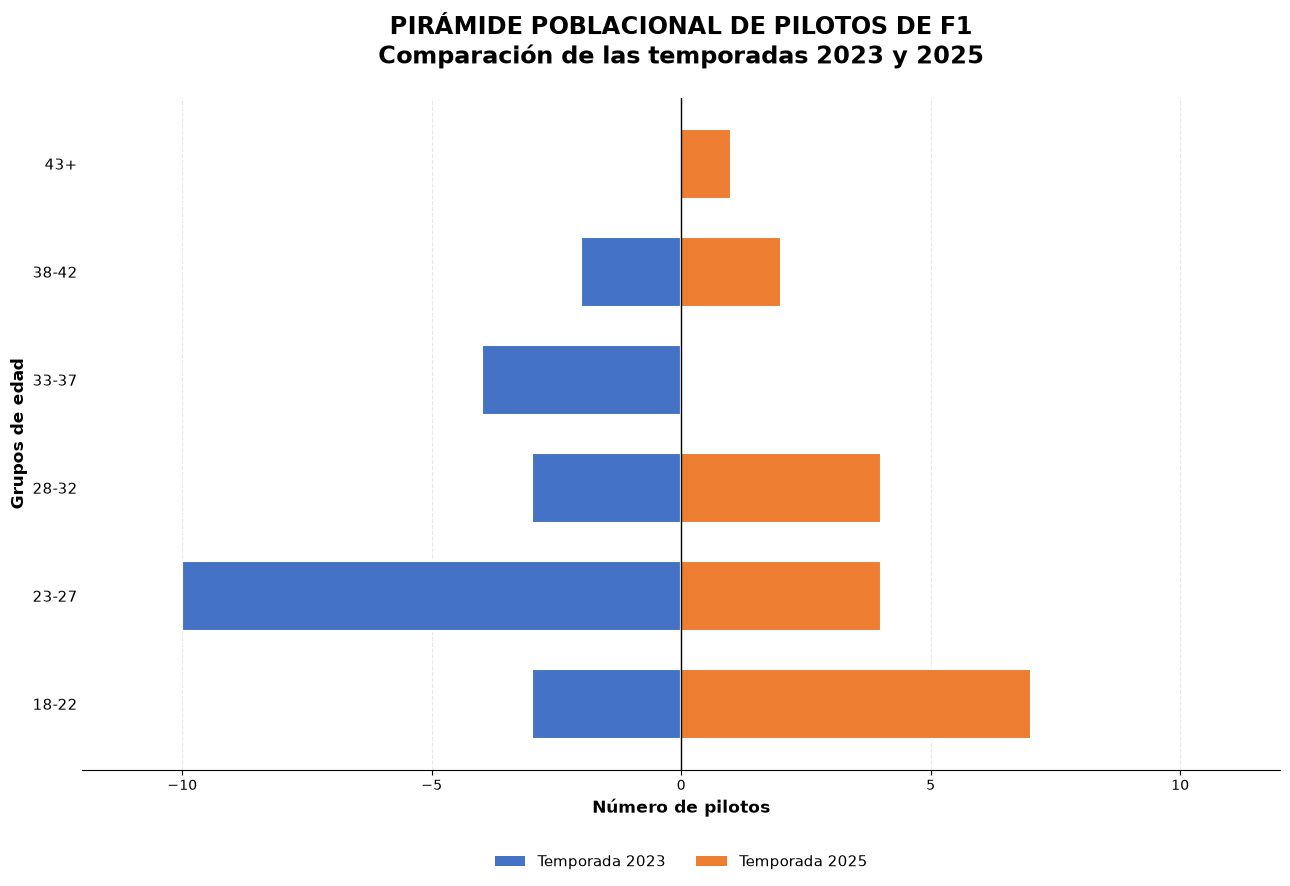

In [34]:
# ==================================================
# 7. DIBUJAR LA PIRÁMIDE POBLACIONAL
# ==================================================

fig, ax = plt.subplots(
    figsize=(13, 9)
)

# Datos de cada temporada
valores_2023 = resumen[2023]
valores_2025 = resumen[2025]

# Colores
color_2023 = "#4472C4"
color_2025 = "#ED7D31"

# Barras enfrentadas
barras_2023 = ax.barh(
    GRUPOS_EDAD,
    -valores_2023,
    color=color_2023,
    edgecolor="white",
    linewidth=1.5,
    height=0.65,
    label="Temporada 2023"
)

barras_2025 = ax.barh(
    GRUPOS_EDAD,
    valores_2025,
    color=color_2025,
    edgecolor="white",
    linewidth=1.5,
    height=0.65,
    label="Temporada 2025"
)

# Invertir eje para que los mayores aparezcan arriba
ax.invert_yaxis()

# Línea central
ax.axvline(
    0,
    color="black",
    linewidth=1
)

# Etiquetas de las barras
for barra in barras_2023:

    ancho = barra.get_width()

    if ancho != 0:

        ax.text(
            ancho - 0.15,
            barra.get_y() + barra.get_height() / 2,
            str(abs(int(ancho))),
            ha="right",
            va="center",
            color="white",
            fontweight="bold",
            fontsize=10
        )


for barra in barras_2025:

    ancho = barra.get_width()

    if ancho != 0:

        ax.text(
            ancho + 0.15,
            barra.get_y() + barra.get_height() / 2,
            str(int(ancho)),
            ha="left",
            va="center",
            color="white",
            fontweight="bold",
            fontsize=10
        )

# ==================================================
# 8. PERSONALIZAR EL GRÁFICO
# ==================================================

maximo = max(
    valores_2023.max(),
    valores_2025.max()
)

limite = maximo + 2

ax.set_xlim(
    -limite,
    limite
)

ax.set_xlabel(
    "Número de pilotos",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Grupos de edad",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "PIRÁMIDE POBLACIONAL DE PILOTOS DE F1\n"
    "Comparación de las temporadas 2023 y 2025",
    fontsize=17,
    fontweight="bold",
    pad=25
)

# Leyenda
ax.legend(
    handles=[
        Patch(
            facecolor=color_2023,
            label="Temporada 2023"
        ),
        Patch(
            facecolor=color_2025,
            label="Temporada 2025"
        )
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.17),
    ncol=2,
    frameon=False,
    fontsize=11
)

# Cuadrícula
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Eliminar bordes innecesarios
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=11
)

plt.tight_layout()